# Modeling

### Import Libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import os
import plotly.express as px
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
import umap

from dash import Dash, dcc, html, Input, Output
import plotly.express as px
import plotly.graph_objects as go
import pandas as pd

/mnt/c/Users/frank/cs231-project-fishing/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Constants

In [2]:
PROCESSED_TRSHMNT_DIR_FROM_CWD = "../data/processed/transshipment"
PROCESSED_LOITERING_FILENAME = "processed-loitering-events.csv"

RANDOM_SEED = 21

K_MEANS_N_INIT = 10

### Set Seed for Reproducible Random Number Generation

In [3]:
np.random.seed(RANDOM_SEED)

## Modeling Loitering Events

### Load Processed Dataset

In [4]:
loitering_df = pd.read_csv(
    os.path.join(
        os.getcwd(),
        PROCESSED_TRSHMNT_DIR_FROM_CWD,
        PROCESSED_LOITERING_FILENAME
    )
)
loitering_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 46569 entries, 0 to 46568
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   transshipment_mmsi    46569 non-null  int64  
 1   starting_latitude     46569 non-null  float64
 2   starting_longitude    46569 non-null  float64
 3   ending_latitude       46569 non-null  float64
 4   ending_longitude      46569 non-null  float64
 5   starting_timestamp    46569 non-null  str    
 6   ending_timestamp      46569 non-null  str    
 7   median_speed_knots    46569 non-null  float64
 8   total_event_duration  46569 non-null  float64
 9   diff_lat              46569 non-null  float64
 10  diff_long             46569 non-null  float64
 11  movement_mag          46569 non-null  float64
 12  local_hour            46569 non-null  float64
 13  is_night_corrected    46569 non-null  int64  
 14  nearest_mpa_name      46569 non-null  str    
 15  nearest_mpa_lat       46569 no

### 1. Principal Component Analysis (PCA)

#### 1. Select and Scale Features

In [5]:
loitering_PCA_features = ['total_event_duration', 'median_speed_knots', 'nearest_mpa_dist', 'movement_mag', 'local_hour', 'is_night_corrected']

loitering_PCA_X = loitering_df[loitering_PCA_features]

loitering_PCA_scaler = StandardScaler()
loitering_PCA_X_scaled = loitering_PCA_scaler.fit_transform(loitering_PCA_X)

#### 2. Analyze Explained Variance

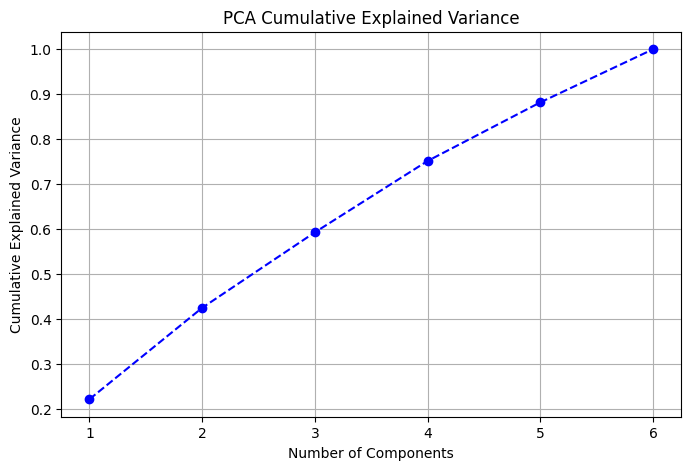

In [6]:
loitering_PCA_full = PCA()
loitering_PCA_full.fit(loitering_PCA_X_scaled)
cum_sum = np.cumsum(loitering_PCA_full.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_sum) + 1), cum_sum, marker='o', linestyle='--', color='b')
plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.grid()
plt.show()

Each PC explains 10-20% varience. Five components explain ~88% of the varience.

#### 3. Reduce Features to 5 Principal Components

In [7]:
n_components = 5
loitering_PCA = PCA(n_components=n_components)
loitering_X_PCA = loitering_PCA.fit_transform(loitering_PCA_X_scaled)

In [8]:
loadings = pd.DataFrame(
    loitering_PCA.components_.T,
    columns=[f"PC{i}" for i in range(1, n_components+1)],
    index=loitering_PCA_features
)

print(loadings)

                           PC1       PC2       PC3       PC4       PC5
total_event_duration -0.481238 -0.420767  0.175158  0.399863  0.344660
median_speed_knots    0.544762  0.420587  0.078924 -0.070986  0.422709
nearest_mpa_dist      0.471982 -0.134250  0.164214  0.740795  0.162707
movement_mag         -0.003562 -0.007374  0.962508 -0.241185 -0.086040
local_hour           -0.444373  0.526649  0.025185  0.025368  0.601219
is_night_corrected   -0.226709  0.592136  0.095225  0.476948 -0.554243


#### 4. Principle Component (PC) Interpretation

| Component | Dominant Features | Behavioral Label | Interpretation |
| ----------|-------------------|------------------|----------------|
 | PC1 | median_speed_knots(+0.54) total_event_duration(-0.48) nearest_mpa_dist(+0.47) | Persistence vs. Transit | Captures the trade-off between moving and staying. Low values indicate long-duration loitering at low speeds, while high values represent faster transit further from MPAs. |
| PC2 | is_night_corrected(+0.59) local_hour(+0.52) total_event_duration(-0.42) | Nocturnal Cover | Distinguishes between day and night activity. High values represent nighttime behavior, potentially used to mask activities from visual surveillance. |
| PC3 | movement_mag(+0.96) | Stationary vs. Drift | Almost exclusively captures spatial displacement. Distinguishes between vessels that are anchored or tied up (low movement) and those drifting with currents (high movement). |
| PC4 | nearest_mpa_dist(+0.74) is_night_corrected(+0.48) | Contextual Stealth | Identifies behavior relative to protected zones. High values indicate nighttime loitering specifically in the open ocean (high distance), while low values indicate proximity to MPAs. |
| PC5 | local_hour(+0.60) is_night_corrected(-0.55) median_speed_knots(+0.42) | Dusk/Dawn Transit | Captures the relationship between local time and speed. Likely distinguishes "commute" behavior or vessels moving quickly just before or after the night threshold. |

### 2. K-Means Clustering

#### 1. Test Clusters with Varying Ks

In [9]:
wcss = []
silhouette_avg = []
k_range = range(2, 10)

for k in k_range:
    k_means = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=K_MEANS_N_INIT)
    cluster_labels = k_means.fit_predict(loitering_X_PCA)

    # WCSS (Inertia)
    wcss.append(k_means.inertia_)

    # Silhouette Score (Closer to 1 is better)
    silhouette_avg.append(silhouette_score(loitering_X_PCA, cluster_labels))

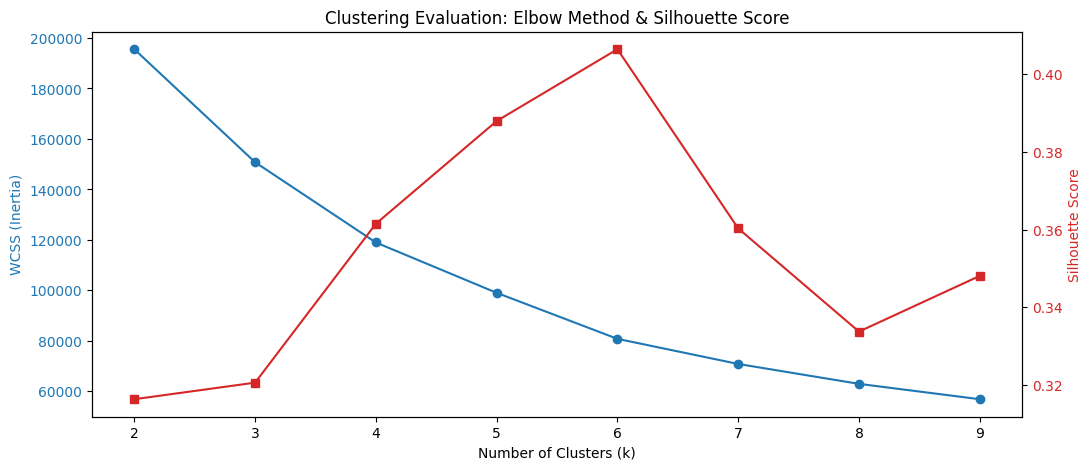

In [10]:
# Plotting Elbow and Silhouette side-by-side
fig, ax1 = plt.subplots(figsize=(12, 5))

# Elbow Plot (WCSS)
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('WCSS (Inertia)', color='tab:blue')
ax1.plot(k_range, wcss, marker='o', color='tab:blue', label='WCSS')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# Silhouette Plot
ax2 = ax1.twinx()
ax2.set_ylabel('Silhouette Score', color='tab:red')
ax2.plot(k_range, silhouette_avg, marker='s', color='tab:red', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Clustering Evaluation: Elbow Method & Silhouette Score')
plt.show()

Choosing K=6 results in the highest silhouette score and the 'elbow' for WCSS

#### 2. Create Chosen Cluster of K=6

In [11]:
chosen_k = 6

k_means_final = KMeans(n_clusters=chosen_k, random_state=RANDOM_SEED, n_init=K_MEANS_N_INIT)
cluster_labels = k_means_final.fit_predict(loitering_X_PCA)

centers = k_means_final.cluster_centers_
cls_labels = [f"Cluster {i}" for i in range(len(centers))]

cls_means = pd.DataFrame(centers, columns=loadings.columns, index=cls_labels)
print(cls_means)

                PC1       PC2        PC3       PC4       PC5
Cluster 0  0.175000 -0.583635  -0.227345 -0.830729  0.344121
Cluster 1 -0.821633  1.346337   0.026755  0.255275  0.138352
Cluster 2  0.368159 -0.025484  -0.053589  0.182737 -1.474060
Cluster 3 -2.541199 -1.911817   0.366955  1.011459  0.668404
Cluster 4  1.415084 -0.510277   0.261317  1.262664  0.277992
Cluster 5 -0.118442 -0.097812  26.015279 -6.411586 -2.097889


#### Cluster Interpretation

| Cluster Num | PCA Signatures |	Behavioral Label	| Description |
|-------------|----------------|------------------------|-------------|
| Cluster 0 |	Moderate PC1, Low PC2 |	Standard Daytime Operations |	Routine maritime activity occurring during the day with average speed and duration, typically located at a safe distance from protected zones. |
| Cluster 1 |	Low PC1, High PC2 |	Nighttime Stealth Loitering	Highest Risk. | These vessels exhibit long event durations at low speeds specifically during night hours. This is a primary indicator of suspicious activity near MPA borders. |
| Cluster 2 |	High PC1, Very Low PC5 | 	Nocturnal Transit |	Vessels moving at moderate speeds during the evening or night. Likely represents "commuter" behavior or ships repositioning for the next day's work. |
| Cluster 3 |	Extremely Low PC1 & PC2 |	Persistent Daytime Loitering |	These vessels stay stationary for the longest periods but operate primarily during daylight. Likely large tankers or supply vessels engaged in legitimate, long-term transshipment. |
| Cluster 4 |	High PC1, High PC4 |	Open-Sea Transit 	Low Risk. | Characterized by higher speeds, shorter durations, and significant distance from MPAs. These are likely merchant vessels passing through the region. |
| Cluster 5 | 	Massive PC3, Low PC4 |	High-Drift MPA Proximity |	Unique outliers that show extreme spatial displacement (drift) while remaining very close to MPA boundaries. Could represent vessels "grazing" protected edges due to currents. |

#### 3. Visualize Chosen Cluster using UMAP Reduction

In [26]:
reducer = umap.UMAP(n_components=2, random_state=RANDOM_SEED)
loitering_X_UMAP = reducer.fit_transform(loitering_X_PCA)

/mnt/c/Users/frank/cs231-project-fishing/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


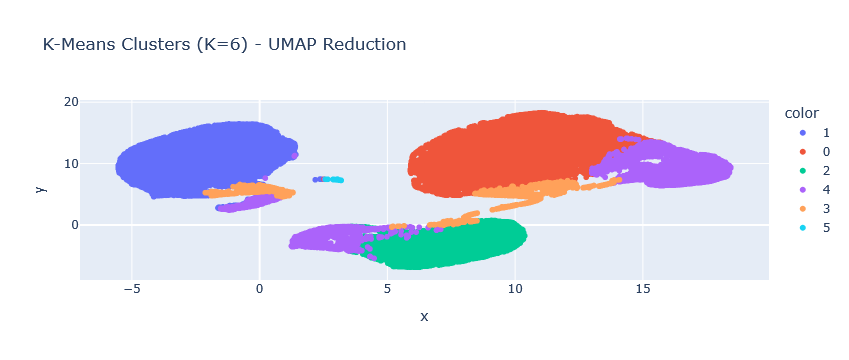

In [13]:
fig = px.scatter(x=loitering_X_UMAP[:, 0], y=loitering_X_UMAP[:, 1],
                 color=cluster_labels.astype(str),
                 title=f'K-Means Clusters (K={chosen_k}) - UMAP Reduction')
fig.show()

In [12]:

# Prepare the data
loitering_nearest_mpa = loitering_df.copy()
loitering_nearest_mpa['cluster'] = cluster_labels.astype(int)
loitering_nearest_mpa['pca_1'] = loitering_X_PCA[:, 0]
loitering_nearest_mpa['pca_2'] = loitering_X_PCA[:, 1]

# Map cluster numbers to behavioral labels
cluster_names = {
    1: "Nighttime MPA Border Activity (Suspicious)",
    3: "Long-Term Daytime Loitering",
    4: "Open-Sea High-Speed Transit",
    5: "High-Drift MPA Proximity",
    0: "Standard Daytime Operations",
    2: "Nocturnal Transit/Evening Activity"
}
loitering_nearest_mpa['behavior_type'] = loitering_nearest_mpa['cluster'].map(cluster_names)

# 2. Initialize Dash App
app = Dash(__name__)

app.layout = html.Div([
    html.Div([
        html.H1("Vessel Clustering & MPA Analytics", style={'textAlign': 'center', 'fontFamily': 'Arial'}),
        html.P("Interactive Behavioral Dashboard", 
               style={'textAlign': 'center', 'color': '#7f8c8d'})
    ], style={'padding': '20px', 'backgroundColor': '#f8f9fa', 'borderBottom': '1px solid #ddd'}),

    html.Div([
        # Sidebar
        html.Div([
            html.H4("Analysis Controls"),
            html.Label("Select Behavior Cluster:"),
            dcc.Dropdown(
                id='cluster-dropdown',
                # Added 'All Clusters' option
                options=[{'label': "All Clusters", "value": "ALL"}] + 
                        [{'label': f"Cluster {k}: {v}", 'value': k} for k, v in cluster_names.items()],
                value="ALL", 
                clearable=False
            ),
            html.Hr(),
            html.Div(id='cluster-stats', style={'fontSize': '14px'})
        ], style={'width': '20%', 'display': 'inline-block', 'padding': '20px', 'verticalAlign': 'top'}),

        # Main Visualization Pane
        html.Div([
            dcc.Graph(id='global-map', style={'height': '600px'}),
        ], style={'width': '78%', 'display': 'inline-block'})
    ])
])

# 3. Callbacks for Interactivity
@app.callback(
    [Output('global-map', 'figure'),
     Output('cluster-stats', 'children')],
    [Input('cluster-dropdown', 'value')]
)
def update_dashboard(selected_cluster):
    
    # Logic to handle 'ALL' or specific cluster selection
    if selected_cluster == "ALL":
        display_df = loitering_nearest_mpa
        title_suffix = "All Behavior Profiles"
    else:
        display_df = loitering_nearest_mpa[loitering_nearest_mpa['cluster'] == selected_cluster]
        title_suffix = f"Profile: {cluster_names[selected_cluster]}"
    
    # Map Visualization
    # Using 'color' automatically generates a legend
    fig_map = px.scatter_map(
        display_df, 
        lat="starting_latitude", 
        lon="starting_longitude",
        color="behavior_type", # This creates the legend and color coding
        hover_name="transshipment_mmsi", 
        hover_data=["total_event_duration", "nearest_mpa_name", "median_speed_knots"],
        zoom=1, 
        height=600,
        title=f"Global Vessel Distribution - {title_suffix}",
        # Custom color map to highlight the suspicious cluster 1 in red
        color_discrete_map={
            cluster_names[1]: "#e74c3c", # Red
            cluster_names[3]: "#f1c40f", # Yellow
            cluster_names[4]: "#2ecc71", # Green
            cluster_names[5]: "#9b59b6", # Purple
            cluster_names[0]: "#3498db", # Blue
            cluster_names[2]: "#e67e22"  # Orange
        }
    )
    
    fig_map.update_layout(
        mapbox_style="carto-darkmatter", 
        margin={"r":0,"t":40,"l":0,"b":0},
        legend=dict(yanchor="top", y=0.99, xanchor="left", x=0.01, bgcolor="rgba(255,255,255,0.5)")
    )

    # Statistical summaries
    stats = [
        html.P([html.B("Total Events: "), f"{len(display_df):,}"]),
        html.P([html.B("Avg Duration: "), f"{display_df['total_event_duration'].mean():.2f} hrs"]),
        html.P([html.B("Avg Speed: "), f"{display_df['median_speed_knots'].mean():.2f} knots"])
    ]

    return fig_map, stats

if __name__ == '__main__':
    app.run(debug=True)

## Calculate P-Value for Cluster 1

Observed Mean Distance for Cluster 1: 8.27
Running 10000 permutations...
------------------------------
Calculated P-Value: 0.0
Bonferroni Corrected Threshold (Alpha/6): 0.008333333333333333


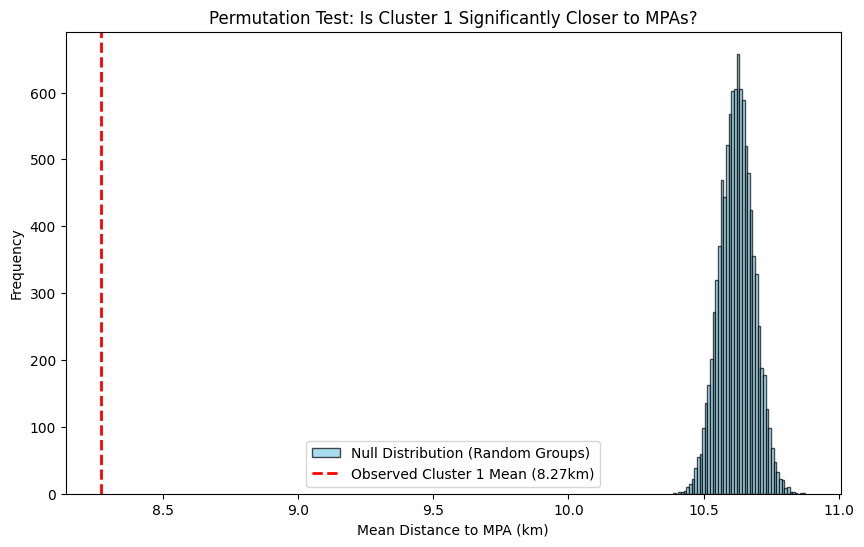

In [14]:

observed_mean_dist = loitering_nearest_mpa[loitering_nearest_mpa['cluster'] == 1]['nearest_mpa_dist'].mean()
print(f"Observed Mean Distance for Cluster 1: {observed_mean_dist:.2f}")

# 2. Permutation Test (The "Shuffle")
n_permutations = 10000
permuted_means = []

# We fix the size of the cluster but shuffle which ships are actually in it
cluster_size = len(loitering_nearest_mpa[loitering_nearest_mpa['cluster'] == 1])
all_distances = loitering_nearest_mpa['nearest_mpa_dist'].values

print(f"Running {n_permutations} permutations...")
for _ in range(n_permutations):
    # Randomly pick a group of ships the same size as Cluster 1
    shuffle = np.random.choice(all_distances, size=cluster_size, replace=False)
    permuted_means.append(np.mean(shuffle))

# 3. Calculate P-Value
# The proportion of times a random group was closer (or as close) to an MPA as Cluster 1
p_value = np.sum(np.array(permuted_means) <= observed_mean_dist) / n_permutations

# 4. Apply Bonferroni Correction
n_clusters = 6
alpha = 0.05
corrected_threshold = alpha / n_clusters

print("-" * 30)
print(f"Calculated P-Value: {p_value}")
print(f"Bonferroni Corrected Threshold (Alpha/6): {corrected_threshold}")

plt.figure(figsize=(10, 6))
plt.hist(permuted_means, bins=50, color='skyblue', edgecolor='black', alpha=0.7, label='Null Distribution (Random Groups)')
plt.axvline(observed_mean_dist, color='red', linestyle='dashed', linewidth=2, label=f'Observed Cluster 1 Mean ({observed_mean_dist:.2f}km)')
plt.title("Permutation Test: Is Cluster 1 Significantly Closer to MPAs?")
plt.xlabel("Mean Distance to MPA (km)")
plt.ylabel("Frequency")
plt.legend()
plt.show()